# 2 - Preparação dos dados: construção da amostra

A base do HMDA tem 13,5 milhões de pedidos de crédito de todos os tipos, para responder à nossa pergunta, precisamos comparar homens e mulheres em **situações equivalentes**.
Então precisamos:

1. aplicar os filtros definidos no protocolo e registrar quantas linhas saem em cada um
2. remover atributos irrelevantes e criar as variáveis de interesse
3. identificar os valores ausentes e verificar se eles são aleatórios
4. gerar duas bases: uma principal, só com casos completos, e uma alternativa, com os faltantes preenchidos, para testar a robustez dos resultados...

### 1. Bibliotecas utilizadas

In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Define sementes aleatórias para reprodutibilidade.
random.seed(42)
np.random.seed(42)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)

ARQUIVO = "../data/hmda_2025.parquet"
os.makedirs("../figuras", exist_ok=True)

### 2. Leitura dos atributos usados nos filtros

O Parquet permite ler só algumas colunas, vamos carregar primeiro apenas as 10 colunas usadas nos filtros.

No HMDA, as variáveis categóricas são códigos numéricos (por exemplo, **action_taken = 3** significa "pedido negado"). O significado de cada código está no [dicionário de dados](https://ffiec.cfpb.gov/documentation/publications/loan-level-datasets/lar-data-fields).

In [2]:
colunas_filtro = ["action_taken", "loan_purpose", "occupancy_type", "total_units", "lien_status",
                  "business_or_commercial_purpose", "open_end_line_of_credit", "reverse_mortgage",
                  "co_applicant_sex", "derived_sex"]

data = pd.read_parquet(ARQUIVO, columns=colunas_filtro)

print("Número de linhas e colunas:", data.shape)
data.head(10)

Número de linhas e colunas: (13543606, 10)


,action_taken,loan_purpose,occupancy_type,total_units,lien_status,business_or_commercial_purpose,open_end_line_of_credit,reverse_mortgage,co_applicant_sex,derived_sex
0,1,1,1,1,1,2,2,2,5,Male
1,1,1,3,1,1,2,2,2,5,Female
2,1,1,1,1,1,2,2,2,2,Female
3,1,32,3,1,1,1,2,2,2,Joint
4,1,31,3,>149,1,1,2,2,5,Sex Not Available
5,1,1,2,1,1,1,2,2,5,Sex Not Available
6,1,32,3,2,1,1,2,2,5,Sex Not Available
7,1,1,3,5-24,1,1,2,2,5,Sex Not Available
8,1,1,3,1,1,1111,1111,1111,5,Female
9,1,31,1,1,1,1111,1111,1111,5,Male


### 3. Filtros da amostra

Cada filtro tem uma justificativa ver em docs/protocolo.md:

| Filtro | Por quê |
|---|---|
| action_taken = 1 (aprovado) ou 3 (negado) | Só pedidos com decisão final de crédito; exclui desistências e pedidos incompletos |
| loan_purpose = 1 (compra) | Refinanciamento tem outra dinâmica de risco |
| occupancy_type = 1 (residência principal) | Investimento e segunda moradia têm critérios diferentes |
| total_units de 1 a 4 | Crédito residencial (exclui prédios) |
| lien_status = 1 (primeira hipoteca) | Segunda hipoteca tem outro risco |
| business_or_commercial_purpose = 2 (não) | Apenas crédito ao consumidor |
| open_end_line_of_credit = 2 (não) | Linha de crédito rotativa é outro produto |
| reverse_mortgage = 2 (não) | Hipoteca reversa é um produto específico para idosos |
| co_applicant_sex = 5 (sem co-candidato) | Com dois solicitantes, o gênero do pedido fica ambíguo |
| derived_sex = Male ou Female | Exclui pedidos conjuntos e sem informação de sexo |


In [3]:
fluxo = [("Base completa HMDA 2025", len(data))]

data = data[data["action_taken"].isin(["1", "3"])]
fluxo.append(("Aprovado ou negado", len(data)))

data = data[data["loan_purpose"] == "1"]
fluxo.append(("Compra de imóvel", len(data)))

data = data[data["occupancy_type"] == "1"]
fluxo.append(("Residência principal", len(data)))

data = data[data["total_units"].isin(["1", "2", "3", "4"])]
fluxo.append(("1 a 4 unidades", len(data)))

data = data[data["lien_status"] == "1"]
fluxo.append(("Primeira hipoteca", len(data)))

data = data[data["business_or_commercial_purpose"] == "2"]
fluxo.append(("Sem finalidade comercial", len(data)))

data = data[data["open_end_line_of_credit"] == "2"]
fluxo.append(("Sem linha de crédito aberta", len(data)))

data = data[data["reverse_mortgage"] == "2"]
fluxo.append(("Sem hipoteca reversa", len(data)))

data = data[data["co_applicant_sex"] == "5"]
fluxo.append(("Sem co-candidato", len(data)))

data = data[data["derived_sex"].isin(["Male", "Female"])]
fluxo.append(("Sexo: homem ou mulher", len(data)))

fluxograma = pd.DataFrame(fluxo, columns=["Etapa", "Linhas restantes"])
fluxograma["Removidas"] = -fluxograma["Linhas restantes"].diff().fillna(0).astype(int)
fluxograma

,Etapa,Linhas restantes,Removidas
0,Base completa HMDA 2025,13543606,0
1,Aprovado ou negado,8942981,4600625
2,Compra de imóvel,4199851,4743130
3,Residência principal,3689287,510564
4,1 a 4 unidades,3689186,101
5,Primeira hipoteca,3518731,170455
6,Sem finalidade comercial,3435124,83607
7,Sem linha de crédito aberta,3409972,25152
8,Sem hipoteca reversa,3409746,226
9,Sem co-candidato,1850476,1559270


### 4. Leitura dos atributos da análise

- **alvo**: action_taken (aprovado ou negado);
- **gênero**: derived_sex;
- **risco do solicitante**: renda (income), comprometimento de renda (debt_to_income_ratio abreviação: DTI), valor financiado sobre valor do imóvel (combined_loan_to_value_ratio abreviação: LTV), valor do empréstimo e do imóvel, prazo, tipo de empréstimo e idade;
- **localização**: instituição (lei), estado e características do setor censitário;
- **preço** (usado só na hipótese H3, para os aprovados): taxa de juros, rate_spread e custos.

Todos os outros atributos são considerados irrelevantes para a pergunta e não são lidos.

In [4]:
colunas_analise = ["lei", "state_code", "action_taken", "derived_sex",
                   "income", "debt_to_income_ratio", "combined_loan_to_value_ratio",
                   "loan_amount", "property_value", "loan_term", "loan_type", "applicant_age",
                   "derived_race", "derived_ethnicity", "construction_method",
                   "tract_minority_population_percent", "tract_to_msa_income_percentage",
                   "interest_rate", "rate_spread", "total_loan_costs", "denial_reason_1"]

filtros = [("action_taken", "in", ["1", "3"]),
           ("loan_purpose", "==", "1"),
           ("occupancy_type", "==", "1"),
           ("total_units", "in", ["1", "2", "3", "4"]),
           ("lien_status", "==", "1"),
           ("business_or_commercial_purpose", "==", "2"),
           ("open_end_line_of_credit", "==", "2"),
           ("reverse_mortgage", "==", "2"),
           ("co_applicant_sex", "==", "5"),
           ("derived_sex", "in", ["Male", "Female"])]

data = pd.read_parquet(ARQUIVO, columns=colunas_analise, filters=filtros)

print("Número de linhas e colunas:", data.shape)
data.head(10)

Número de linhas e colunas: (1761311, 21)


,lei,state_code,action_taken,derived_sex,income,debt_to_income_ratio,combined_loan_to_value_ratio,loan_amount,property_value,loan_term,loan_type,applicant_age,derived_race,derived_ethnicity,construction_method,tract_minority_population_percent,tract_to_msa_income_percentage,interest_rate,rate_spread,total_loan_costs,denial_reason_1
0,549300QFJDBOCX7WKY08,TX,1,Male,65,44,97,305000,315000,360,1,25-34,White,Hispanic or Latino,1,95.09,38.0,5.375,-0.676,7234.4,10
1,549300HW662MN1WU8550,CA,1,Female,178,42,80,665000,835000,360,1,35-44,White,Not Hispanic or Latino,1,45.67,104.0,6.625,0.169,7728.95,10
2,549300HW662MN1WU8550,CA,1,Male,61,50%-60%,96.5,255000,265000,360,2,<25,American Indian or Alaska Native,Hispanic or Latino,1,90.62,79.0,5.875,0.750,15920.84,10
3,549300HW662MN1WU8550,MN,1,Female,69,20%-<30%,97,145000,145000,360,1,25-34,White,Not Hispanic or Latino,1,19.21,124.0,6.499,0.414,7826.8,10
4,549300D36J5CQX0I4F44,MI,1,Male,59,20%-<30%,98.189,175000,175000,360,2,<25,White,Not Hispanic or Latino,1,33.24,102.0,5.990,0.648,4541.31,10
5,549300D36J5CQX0I4F44,MI,1,Male,62,38,90.000,245000,275000,360,1,<25,White,Not Hispanic or Latino,1,20.32,149.0,6.625,0.358,5136.70,10
6,549300D36J5CQX0I4F44,OH,1,Female,54,30%-<36%,98.188,145000,155000,360,2,35-44,White,Hispanic or Latino,1,66.35,39.0,7.625,1.848,NA,10
7,549300D36J5CQX0I4F44,OH,1,Female,39,47,98.188,95000,105000,360,2,55-64,White,Not Hispanic or Latino,1,62.4,26.0,7.250,1.341,3168.75,10
8,54930063578UDYE3JR69,OH,1,Female,79,38,90,215000,235000,360,1,65-74,White,Not Hispanic or Latino,1,15.45,89.0,7.5,0.9060,2534.5,10
9,54930063578UDYE3JR69,OH,1,Male,42,48,41.83,165000,405000,360,1,55-64,White,Not Hispanic or Latino,1,11.32,124.0,7,0.2820,2395.5,10


### 5. Criação das variáveis de interesse

Transformamos as duas variáveis principais em binárias (0 ou 1):
- `negado` = 1 se o pedido foi negado (action_taken = 3), e 0 se foi aprovado;
- `mulher` = 1 se o solicitante é mulher, e 0 se é homem.

Depois disso, action_taken e derived_sex são removidas, pois a informação já está nas novas colunas.

In [5]:
data["negado"] = (data["action_taken"] == "3").astype(int)
data["mulher"] = (data["derived_sex"] == "Female").astype(int)

data = data.drop(["action_taken", "derived_sex"], axis=1)

print("Pedidos negados:", data["negado"].sum(), f"({data['negado'].mean():.1%})")
print("Mulheres:       ", data["mulher"].sum(), f"({data['mulher'].mean():.1%})")

Pedidos negados: 290378 (16.5%)
Mulheres:        696469 (39.5%)


### 6. Identificação dos valores faltantes

- NA não se aplica ou não informado
- Exempt instituições pequenas são dispensadas de informar alguns campos
- 8888 idade não informada

In [6]:
data = data.replace(["NA", "Exempt", "8888", ""], np.nan)

print("Valores ausentes por coluna:")
print(data.isnull().sum().sort_values(ascending=False))

Valores ausentes por coluna:
total_loan_costs                     344086
rate_spread                          302188
interest_rate                        290685
combined_loan_to_value_ratio         192754
property_value                        24672
debt_to_income_ratio                  24451
state_code                            17039
income                                13289
loan_term                              3265
applicant_age                           274
lei                                       0
loan_type                                 0
loan_amount                               0
construction_method                       0
derived_ethnicity                         0
derived_race                              0
tract_to_msa_income_percentage            0
tract_minority_population_percent         0
denial_reason_1                           0
negado                                    0
mulher                                    0
dtype: int64


**Atenção:** nem todo valor ausente é um problema de qualidade dos dados. interest_rate, rate_spread, total_loan_costs e loan_term, por exemplo, não existem para pedidos negados sendo que não há empréstimo logo não há taxa. Da mesma forma, denial_reason_1 só existe para os negados. Essas colunas serão usadas apenas nas análises em que fazem sentido.

As variáveis que realmente importam para os modelos são **renda, DTI** e **LTV**.

In [7]:
print("Valores ausentes entre os APROVADOS:")
print(data[data["negado"] == 0][["interest_rate", "rate_spread", "total_loan_costs", "loan_term"]].isnull().mean().round(3))

Valores ausentes entre os APROVADOS:
interest_rate       0.000
rate_spread         0.008
total_loan_costs    0.037
loan_term           0.001
dtype: float64


### 7. Conversão dos tipos

In [8]:
numericas = ["income", "combined_loan_to_value_ratio", "loan_amount", "property_value", "loan_term",
             "tract_minority_population_percent", "tract_to_msa_income_percentage",
             "interest_rate", "rate_spread", "total_loan_costs"]

data[numericas] = data[numericas].astype(float)
data[numericas].describe().T

,count,mean,std,min,25%,50%,75%,max
income,1748022.0,132.291343,887.764816,-52661.000,60.000,85.000,129.000,5.351820e+05
combined_loan_to_value_ratio,1568557.0,169.198507,37938.404840,0.001,80.000,94.868,96.500,2.950000e+07
loan_amount,1761311.0,328464.896319,292447.903677,5000.000,175000.000,275000.000,395000.000,6.310500e+07
property_value,1736639.0,404242.128042,946184.571060,5000.000,215000.000,315000.000,465000.000,8.500050e+08
loan_term,1758046.0,347.441575,39.414458,1.000,360.000,360.000,360.000,4.810000e+02
tract_minority_population_percent,1761311.0,37.151812,25.832348,0.000,16.300,30.620,53.740,1.000000e+02
tract_to_msa_income_percentage,1761311.0,104.294259,41.820380,0.000,80.000,101.000,125.000,5.160000e+02
interest_rate,1470626.0,6.410260,0.938156,0.000,5.999,6.490,6.750,2.000000e+01
rate_spread,1459123.0,0.222666,1.044261,-414.000,-0.191,0.166,0.565,1.925400e+01
total_loan_costs,1417225.0,7809.684605,5789.933723,0.000,4187.980,6415.610,10043.220,1.495393e+06


O DTI (comprometimento da renda com dívidas) tem dados mistos em faixas e valores exatos. Então escolhemos agrupar os valores exatos na faixa 36%-<50%.

In [9]:
print("Valores originais do DTI:")
print(data["debt_to_income_ratio"].value_counts().head(25))

Valores originais do DTI:
debt_to_income_ratio
30%-<36%    235367
50%-60%     207682
20%-<30%    200345
49          109698
>60%         86357
48           76182
44           75764
47           69728
42           68954
43           68693
46           67468
45           66434
<20%         64420
41           63786
40           62404
39           58844
38           54885
37           51650
36           48199
Name: count, dtype: int64


In [10]:
faixas_dti = {"<20%": "<20%", "20%-<30%": "20%-<30%", "30%-<36%": "30%-<36%",
              "50%-60%": "50%-60%", ">60%": ">60%"}
for valor in range(36, 50):
    faixas_dti[str(valor)] = "36%-<50%"

ordem_dti = ["<20%", "20%-<30%", "30%-<36%", "36%-<50%", "50%-60%", ">60%"]
data["dti"] = pd.Categorical(data["debt_to_income_ratio"].map(faixas_dti), categories=ordem_dti, ordered=True)
data = data.drop("debt_to_income_ratio", axis=1)

print("Faixas de DTI:")
print(data["dti"].value_counts(sort=False, dropna=False))

Faixas de DTI:
dti
<20%         64420
20%-<30%    200345
30%-<36%    235367
36%-<50%    942689
50%-60%     207682
>60%         86357
NaN          24451
Name: count, dtype: int64


### 8. Os valores faltantes são aleatórios?

Se renda, DTI ou LTV faltam*mais para um grupo (por exemplo, mais entre negados ou entre mulheres), remover essas linhas pode distorcer os resultados...

In [11]:
chave = ["income", "dti", "combined_loan_to_value_ratio"]
faltantes = data[chave].isnull()

tabela_faltantes = pd.DataFrame({
    "Aprovados": faltantes[data["negado"] == 0].mean(),
    "Negados": faltantes[data["negado"] == 1].mean(),
    "Homens": faltantes[data["mulher"] == 0].mean(),
    "Mulheres": faltantes[data["mulher"] == 1].mean(),
})   

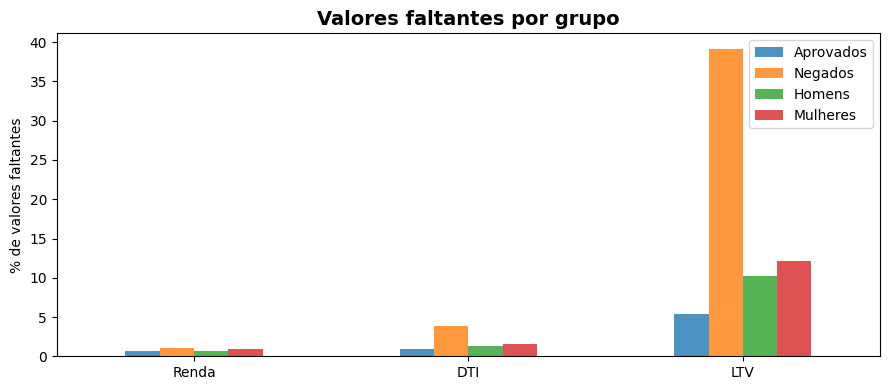

In [12]:
(tabela_faltantes * 100).plot(kind="bar", figsize=(9, 4), alpha=0.8, rot=0)
plt.ylabel("% de valores faltantes")
plt.title("Valores faltantes por grupo", fontsize=14, fontweight="bold")
plt.xticks([0, 1, 2], ["Renda", "DTI", "LTV"])
plt.tight_layout()
plt.savefig("../figuras/faltantes_por_grupo.png", dpi=150)
plt.show()

Os faltantes **não são aleatórios**: o LTV falta em 39,2% dos pedidos negados, contra apenas 5,4% dos aprovados. O DTI também falta mais entre os negados. Entre homens e mulheres, a diferença é pequena.

Uma explicação provável é que, quando o pedido é negado cedo, a instituição não chega a avaliar o imóvel e não calcula o LTV. 
**Consequência:** remover os casos incompletos elimina principalmente pedidos negados, o que reduz artificialmente a taxa de negação. Por isso, a base alternativa é essencial.

### 9. Linhas duplicadas

A base pública não tem um identificador do pedido. Vamos apenas verificar quantas existem, sem remover

In [13]:
print("Número de linhas duplicadas:", data.duplicated().sum())
print(f"Proporção: {data.duplicated().mean():.2%}")

Número de linhas duplicadas: 960
Proporção: 0.05%


### 10. Base principal: casos completos

Na base principal, removemos as linhas com renda, DTI ou LTV faltantes (dropna).

In [14]:
principal = data.dropna(subset=chave)

print("Dimensão antes:", data.shape)
print("Dimensão depois:", principal.shape)
print(f"Linhas removidas: {len(data) - len(principal):,} ({1 - len(principal) / len(data):.1%})")

Dimensão antes: (1761311, 21)
Dimensão depois: (1547246, 21)
Linhas removidas: 214,065 (12.2%)


Vamos verificar se as classes estão balanceadas.

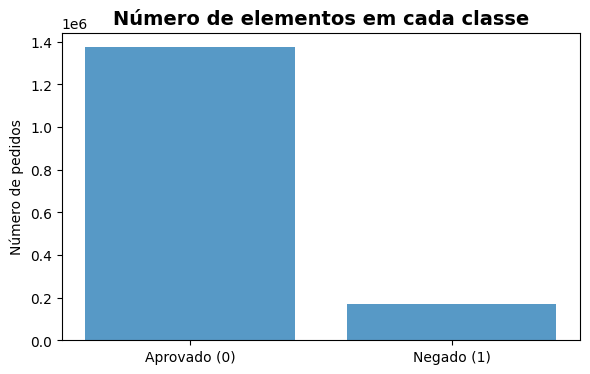

negado
0    1374981
1     172265
Name: count, dtype: int64
Taxa de negação: 11.1%


In [15]:
contagem = principal["negado"].value_counts().sort_index()

plt.figure(figsize=(6, 4))
plt.bar(["Aprovado (0)", "Negado (1)"], contagem.values, alpha=0.75)
plt.title("Número de elementos em cada classe", fontsize=14, fontweight="bold")
plt.ylabel("Número de pedidos")
plt.tight_layout()
plt.savefig("../figuras/balanceamento_classes.png", dpi=150)
plt.show()

print(contagem)
print(f"Taxa de negação: {principal['negado'].mean():.1%}")

As classes são **desbalanceadas**: há muito mais aprovações do que negações.

Taxa bruta de negação por gênero:

In [16]:
principal.groupby("mulher")["negado"].agg(["count", "mean"]).rename(
    index={0: "Homem", 1: "Mulher"}, columns={"count": "Pedidos", "mean": "Taxa de negação"})

,Pedidos,Taxa de negação
mulher,,
Homem,944301,0.105219
Mulher,602945,0.120918


### 11. Base alternativa: preenchimento dos faltantes

Para verificar se a remoção dos casos incompletos muda os resultados e fornecer uma análise de robustex, criamos uma segunda base:
- **renda e LTV**: preenchidos com a mediana
- **DTI**: como é categórica, os faltantes recebem a categoria "Faltante"
- criamos **indicadores** (renda_faltante, ltv_faltante) para que o modelo saiba quais valores foram preenchidos.

> Observação: nos modelos preditivos, a mediana deve ser calculada só no conjunto de **treino**, para não vazar informação do teste. Aqui ela é usada apenas para a análise descritiva de robustez.

In [17]:
alternativa = data.copy()

alternativa["renda_faltante"] = alternativa["income"].isnull().astype(int)
alternativa["ltv_faltante"] = alternativa["combined_loan_to_value_ratio"].isnull().astype(int)

alternativa["income"] = alternativa["income"].fillna(alternativa["income"].median())
alternativa["combined_loan_to_value_ratio"] = alternativa["combined_loan_to_value_ratio"].fillna(
    alternativa["combined_loan_to_value_ratio"].median())
alternativa["dti"] = alternativa["dti"].cat.add_categories("Faltante").fillna("Faltante")

print("Dimensão:", alternativa.shape)
print("\nValores ausentes nas variáveis-chave:")
print(alternativa[chave].isnull().sum())

Dimensão: (1761311, 23)

Valores ausentes nas variáveis-chave:
income                          0
dti                             0
combined_loan_to_value_ratio    0
dtype: int64


### 12. Salvando as bases

In [18]:
principal.to_parquet("../data/amostra_principal.parquet", index=False)
alternativa.to_parquet("../data/amostra_alternativa.parquet", index=False)

print("Base principal:  ", principal.shape)
print("Base alternativa:", alternativa.shape)

Base principal:   (1547246, 21)
Base alternativa: (1761311, 23)
